In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [2]:
train = pd.read_csv("../data/train.csv")

test = pd.read_csv("../data/test.csv")

gender_submission = pd.read_csv("../data/gender_submission.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("Training Dataset Shape:", train.shape)

print("Testing Dataset Shape:", test.shape)

print("Gender Submission Shape:", gender_submission.shape)

Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)
Gender Submission Shape: (418, 2)


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
print(train["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


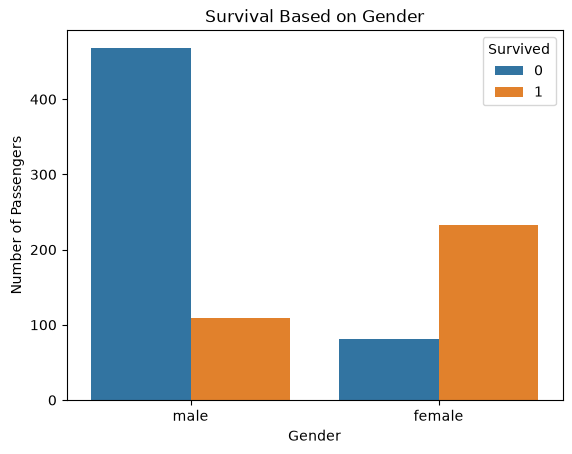

In [10]:
sns.countplot(
    data=train,
    x="Sex",
    hue="Survived"
)

plt.title("Survival Based on Gender")

plt.xlabel("Gender")

plt.ylabel("Number of Passengers")

plt.show()

In [11]:
gender_survival = train.groupby("Sex")["Survived"].mean() * 100

print(gender_survival)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


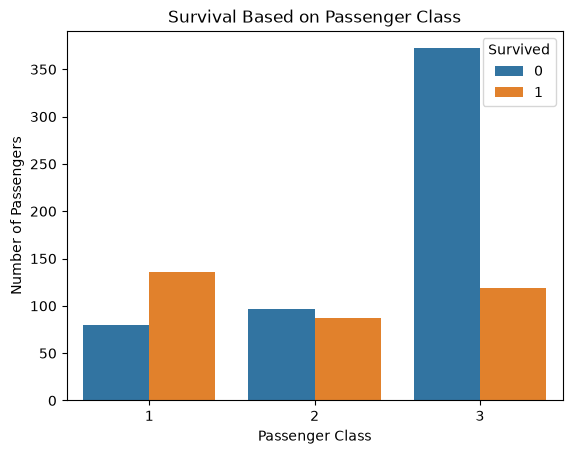

In [12]:
sns.countplot(
    data=train,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival Based on Passenger Class")

plt.xlabel("Passenger Class")

plt.ylabel("Number of Passengers")

plt.show()

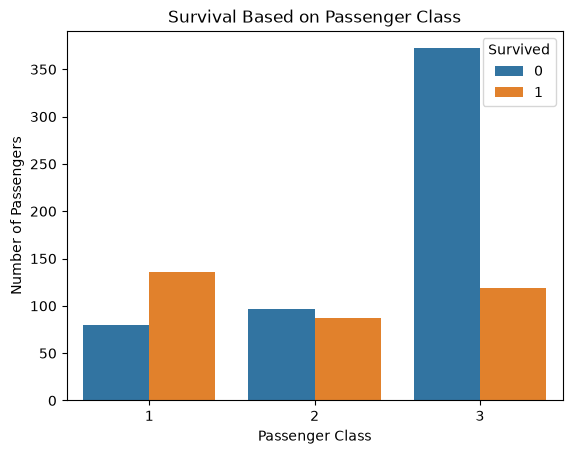

In [13]:
sns.countplot(
    data=train,
    x="Pclass",
    hue="Survived"
)

plt.title("Survival Based on Passenger Class")

plt.xlabel("Passenger Class")

plt.ylabel("Number of Passengers")

plt.show()

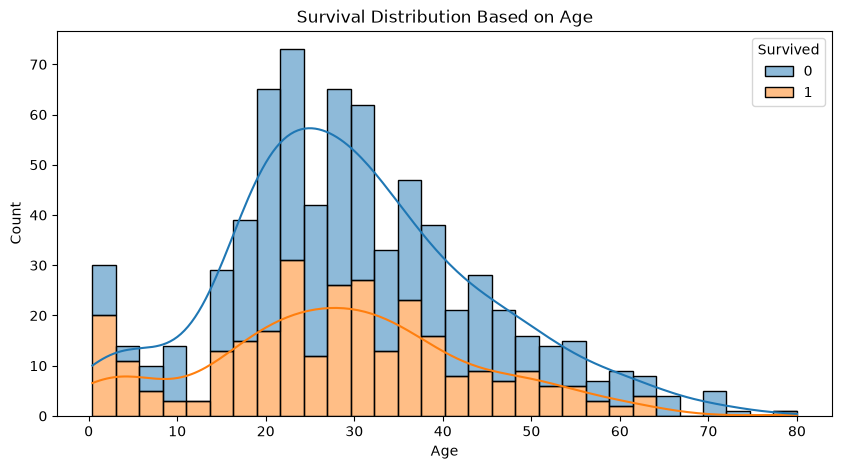

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Survival Distribution Based on Age")

plt.show()

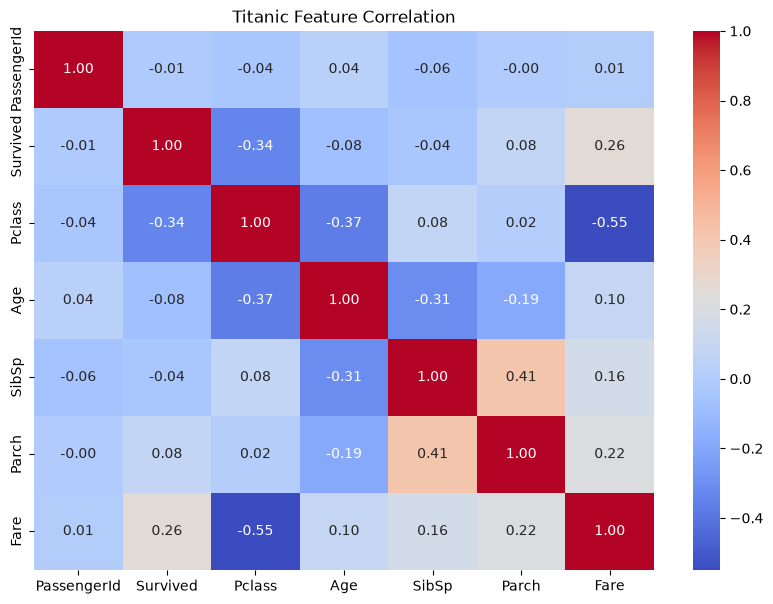

In [15]:
plt.figure(figsize=(10, 7))

correlation = train.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Titanic Feature Correlation")

plt.show()

In [16]:
df = train.copy()

print("Dataset copied successfully!")

df.head()

Dataset copied successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [17]:
df.drop(
    columns=["PassengerId", "Name", "Ticket", "Cabin"],
    inplace=True
)

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [18]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [19]:
df["Age"].fillna(
    df["Age"].median(),
    inplace=True
)

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    28.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [20]:
df["Embarked"].fillna(
    df["Embarked"].mode()[0],
    inplace=True
)

0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: str

In [21]:
print(df.isnull().sum())

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [24]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [25]:
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

In [26]:
df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


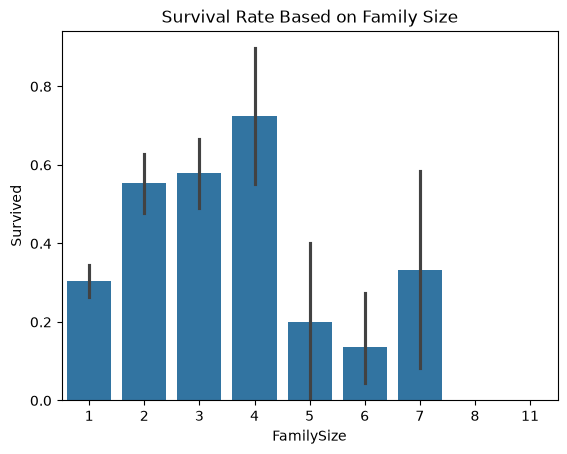

In [27]:
sns.barplot(
    data=df,
    x="FamilySize",
    y="Survived"
)

plt.title("Survival Rate Based on Family Size")

plt.show()

In [32]:
df = pd.get_dummies(
    df,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

KeyError: "None of [Index(['Sex', 'Embarked'], dtype='str')] are in the [columns]"

In [35]:
X = df.drop("Survived", axis=1)

y = df["Survived"]

In [38]:
X = df.drop("Survived", axis=1)

y = df["Survived"]

In [30]:
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,2,0,1,0,1
1,1,1,38.0,1,0,71.2833,2,0,0,0,0
2,1,3,26.0,0,0,7.9250,1,1,0,0,1
3,1,1,35.0,1,0,53.1000,2,0,0,0,1
4,0,3,35.0,0,0,8.0500,1,1,1,0,1


In [39]:
print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (891, 10)
Target Shape: (891,)


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("y_train:", y_train.shape)

print("y_val:", y_val.shape)

X_train: (712, 10)
X_val: (179, 10)
y_train: (712,)
y_val: (179,)


In [45]:
from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score

In [47]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    
    ("classifier", LogisticRegression(max_iter=1000))
])

In [48]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [49]:
print(X_train.isnull().sum())

Pclass          0
Age           137
SibSp           0
Parch           0
Fare            0
FamilySize      0
IsAlone         0
Sex_male        0
Embarked_Q      0
Embarked_S      0
dtype: int64


In [50]:
print("Total missing values:", X_train.isnull().sum().sum())

Total missing values: 137


In [51]:
X_train = X_train.copy()

X_val = X_val.copy()

X_train = X_train.fillna(X_train.median())

X_val = X_val.fillna(X_train.median())

In [52]:
print("Training missing values:")
print(X_train.isnull().sum().sum())

print("Validation missing values:")
print(X_val.isnull().sum().sum())

Training missing values:
0
Validation missing values:
0


In [53]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [54]:
logistic_predictions = logistic_model.predict(X_val)

print("First 20 Predictions:")
print(logistic_predictions[:20])

First 20 Predictions:
[0 0 0 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]


In [55]:
from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(
    y_val,
    logistic_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 80.45 %


In [56]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        logistic_predictions
    )
)

              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [57]:
from sklearn.ensemble import RandomForestClassifier

In [58]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42
)

In [59]:
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [60]:
rf_predictions = random_forest_model.predict(X_val)

print(rf_predictions[:20])

[0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 1]


In [61]:
rf_accuracy = accuracy_score(
    y_val,
    rf_predictions
)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 81.01 %


In [62]:
model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ]

})

print(model_comparison)

                 Model  Accuracy
0  Logistic Regression  0.804469
1        Random Forest  0.810056


In [63]:
print("MODEL PERFORMANCE COMPARISON")
print("-" * 40)

print(f"Logistic Regression: {logistic_accuracy * 100:.2f}%")
print(f"Random Forest:       {rf_accuracy * 100:.2f}%")

MODEL PERFORMANCE COMPARISON
----------------------------------------
Logistic Regression: 80.45%
Random Forest:       81.01%


In [64]:
if logistic_accuracy > rf_accuracy:
    print("Best Model: Logistic Regression")
elif rf_accuracy > logistic_accuracy:
    print("Best Model: Random Forest")
else:
    print("Both models have equal accuracy")

Best Model: Random Forest


In [66]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

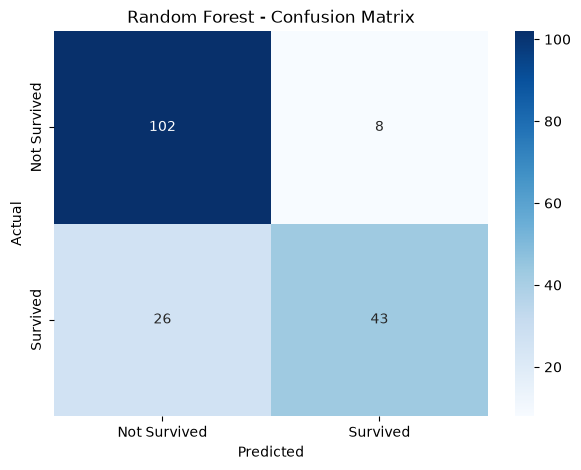

In [67]:
cm = confusion_matrix(y_val, rf_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [68]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("-" * 40)

print(classification_report(y_val, rf_predictions))

Random Forest Classification Report
----------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.93      0.86       110
           1       0.84      0.62      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179



In [69]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)


      Feature  Importance
7    Sex_male    0.400554
4        Fare    0.190074
1         Age    0.128136
0      Pclass    0.122423
5  FamilySize    0.053024
2       SibSp    0.030065
9  Embarked_S    0.027201
3       Parch    0.025756
6     IsAlone    0.013909
8  Embarked_Q    0.008857


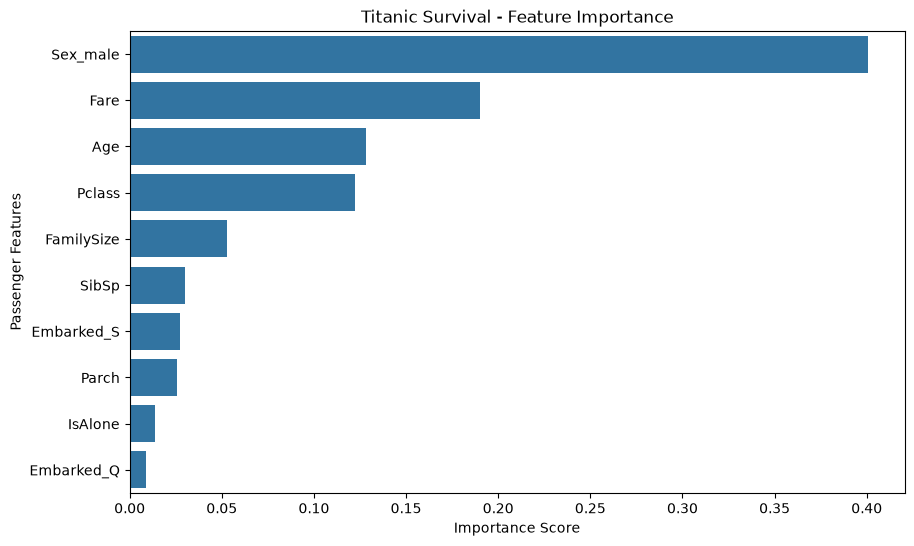

In [70]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Titanic Survival - Feature Importance")

plt.xlabel("Importance Score")
plt.ylabel("Passenger Features")

plt.show()

In [71]:
if logistic_accuracy >= rf_accuracy:

    best_model = logistic_model
    best_model_name = "Logistic Regression"

else:

    best_model = random_forest_model
    best_model_name = "Random Forest"

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [72]:
import pandas as pd
import numpy as np

import joblib

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier

In [73]:
train = pd.read_csv("../data/train.csv")

print("Dataset loaded:", train.shape)

Dataset loaded: (891, 12)


In [74]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = train[features]

y = train["Survived"]

In [75]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = train[features]

y = train["Survived"]

In [76]:
numeric_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Sex",
    "Embarked"
]

In [77]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [78]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [79]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [80]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            random_state=42
        ))
    ]
)

In [81]:
final_model.fit(X, y)

print("Complete ML Pipeline Trained Successfully!")

Complete ML Pipeline Trained Successfully!


In [82]:
joblib.dump(
    final_model,
    "../models/titanic_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [83]:
loaded_model = joblib.load(
    "../models/titanic_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [84]:
test = pd.read_csv("../data/test.csv")

X_test = test[features]

print(X_test.head())

   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  34.5      0      0   7.8292        Q
1       3  female  47.0      1      0   7.0000        S
2       2    male  62.0      0      0   9.6875        Q
3       3    male  27.0      0      0   8.6625        S
4       3  female  22.0      1      1  12.2875        S


In [85]:
predictions = loaded_model.predict(X_test)

print("First 20 predictions:")

print(predictions[:20])

First 20 predictions:
[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1]


In [86]:
probabilities = loaded_model.predict_proba(X_test)

print(probabilities[:5])

[[0.91197263 0.08802737]
 [0.63266409 0.36733591]
 [0.87032652 0.12967348]
 [0.87992424 0.12007576]
 [0.48005962 0.51994038]]


In [87]:
submission = pd.DataFrame({

    "PassengerId": test["PassengerId"],

    "Survived": predictions

})

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [88]:
submission.to_csv(
    "../outputs/submission.csv",
    index=False
)

print("Kaggle submission file generated successfully!")

Kaggle submission file generated successfully!
